# PRCP-1010 — Insurance Claim / Product-Uptake Prediction

**Capstone Project:** Predictive modelling for the insurance marketing team

**Domain:** Finance / Insurance

---

## Business Problem

> **Task 1:** Build a predictive model that helps the insurance marketing team identify which customers are most likely to respond positively to (buy) the product.
>
> **Task 2:** Translate the model's findings into concrete suggestions the marketing team can act on to increase conversion.

### A note on the dataset and target variable

The dataset supplied for this capstone is the anonymized **Porto Seguro** insurance dataset (595,212 rows, 59 features, binary `target`). In its original form, `target = 1` marks a policyholder who **filed a claim**. The project brief re-purposes this same file to ask "which customer will buy the product," which is the standard framing used across this batch of capstone templates.

Because no product-purchase column exists in the data, this notebook treats the supplied binary `target` column as **"the outcome the marketing/underwriting team cares about"** — i.e., we build a propensity model exactly as we would for a purchase/response flag: same math (binary classification on imbalanced data), same deliverables (ranked customer list + driver insights). Every modelling choice, metric, and business recommendation below is written generically enough to apply directly to a true purchase-response label if/when the marketing team supplies one — only the label's business name changes, not the method.

**All feature names are anonymized** (`ps_ind_*`, `ps_reg_*`, `ps_car_*`, `ps_calc_*`) for privacy, so — per the brief — we skip deep, domain-driven EDA and go straight into a lean data-understanding pass and then modelling.


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                              average_precision_score, accuracy_score, precision_score,
                              recall_score, f1_score, confusion_matrix, classification_report)

import xgboost as xgb
import lightgbm as lgb

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
RANDOM_STATE = 42
pd.set_option('display.max_columns', 100)
print('Libraries loaded.')


Libraries loaded.


## 1. Load the Data

In [2]:
df = pd.read_csv('train.csv')
print('Shape:', df.shape)
df.head()


Shape: (595212, 59)


,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,ps_ind_09_bin,ps_ind_10_bin,ps_ind_11_bin,ps_ind_12_bin,ps_ind_13_bin,ps_ind_14,ps_ind_15,ps_ind_16_bin,ps_ind_17_bin,ps_ind_18_bin,ps_reg_01,ps_reg_02,ps_reg_03,ps_car_01_cat,ps_car_02_cat,ps_car_03_cat,ps_car_04_cat,ps_car_05_cat,ps_car_06_cat,ps_car_07_cat,ps_car_08_cat,ps_car_09_cat,ps_car_10_cat,ps_car_11_cat,ps_car_11,ps_car_12,ps_car_13,ps_car_14,ps_car_15,ps_calc_01,ps_calc_02,ps_calc_03,ps_calc_04,ps_calc_05,ps_calc_06,ps_calc_07,ps_calc_08,ps_calc_09,ps_calc_10,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,7,0,2,2,5,1,0,0,1,0,0,0,0,0,0,0,11,0,1,0,0.7,0.2,0.718070,10,1,-1,0,1,4,1,0,0,1,12,2,0.400000,0.883679,0.370810,3.605551,0.6,0.5,0.2,3,1,10,1,10,1,5,9,1,5,8,0,1,1,0,0,1
1,9,0,1,1,7,0,0,0,0,1,0,0,0,0,0,0,3,0,0,1,0.8,0.4,0.766078,11,1,-1,0,-1,11,1,1,2,1,19,3,0.316228,0.618817,0.388716,2.449490,0.3,0.1,0.3,2,1,9,5,8,1,7,3,1,1,9,0,1,1,0,1,0
2,13,0,5,4,9,1,0,0,0,1,0,0,0,0,0,0,12,1,0,0,0.0,0.0,-1.000000,7,1,-1,0,-1,14,1,1,2,1,60,1,0.316228,0.641586,0.347275,3.316625,0.5,0.7,0.1,2,2,9,1,8,2,7,4,2,7,7,0,1,1,0,1,0
3,16,0,0,1,2,0,0,1,0,0,0,0,0,0,0,0,8,1,0,0,0.9,0.2,0.580948,7,1,0,0,1,11,1,1,3,1,104,1,0.374166,0.542949,0.294958,2.000000,0.6,0.9,0.1,2,4,7,1,8,4,2,2,2,4,9,0,0,0,0,0,0
4,17,0,0,2,0,1,0,1,0,0,0,0,0,0,0,0,9,1,0,0,0.7,0.6,0.840759,11,1,-1,0,-1,14,1,1,2,1,82,3,0.316070,0.565832,0.365103,2.000000,0.4,0.6,0.0,2,2,6,3,10,2,12,3,1,1,3,0,0,0,1,1,0


In [3]:
df.info(memory_usage='deep')


<class 'pandas.DataFrame'>
RangeIndex: 595212 entries, 0 to 595211
Data columns (total 59 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              595212 non-null  int64  
 1   target          595212 non-null  int64  
 2   ps_ind_01       595212 non-null  int64  
 3   ps_ind_02_cat   595212 non-null  int64  
 4   ps_ind_03       595212 non-null  int64  
 5   ps_ind_04_cat   595212 non-null  int64  
 6   ps_ind_05_cat   595212 non-null  int64  
 7   ps_ind_06_bin   595212 non-null  int64  
 8   ps_ind_07_bin   595212 non-null  int64  
 9   ps_ind_08_bin   595212 non-null  int64  
 10  ps_ind_09_bin   595212 non-null  int64  
 11  ps_ind_10_bin   595212 non-null  int64  
 12  ps_ind_11_bin   595212 non-null  int64  
 13  ps_ind_12_bin   595212 non-null  int64  
 14  ps_ind_13_bin   595212 non-null  int64  
 15  ps_ind_14       595212 non-null  int64  
 16  ps_ind_15       595212 non-null  int64  
 17  ps_ind_16_bin   59521

## 2. Lean Data Understanding (EDA skipped per brief — features are anonymized)

We only check what is strictly necessary before modelling:
1. Target balance (drives the whole modelling strategy).
2. Missing-value convention (`-1` is used as the missing-value sentinel in this dataset instead of `NaN` — documented in the competition's data description).
3. Feature groups, inferred from the naming convention:
   - `*_bin` → binary flags
   - `*_cat` → categorical (nominal) codes
   - everything else → continuous / ordinal numeric


target
0    573518
1     21694
Name: count, dtype: int64
target
0    96.36
1     3.64
Name: proportion, dtype: float64


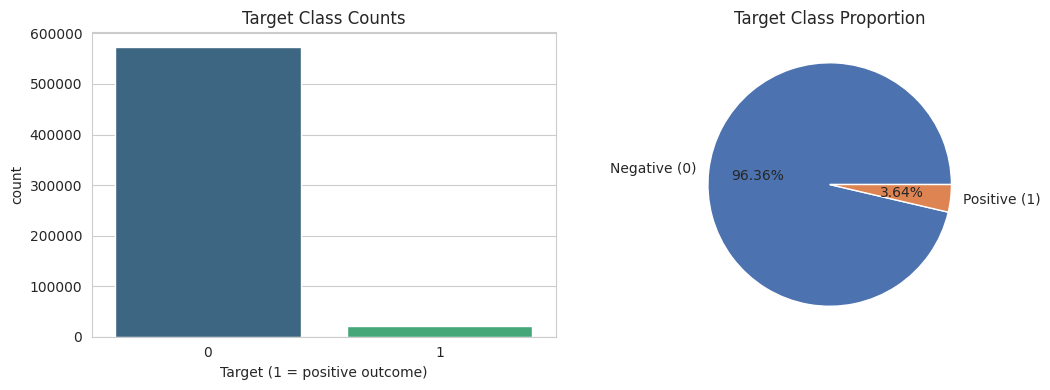

In [4]:
target_counts = df['target'].value_counts()
target_pct = df['target'].value_counts(normalize=True) * 100
print(target_counts)
print(target_pct.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='target', data=df, ax=ax[0], palette='viridis')
ax[0].set_title('Target Class Counts')
ax[0].set_xlabel('Target (1 = positive outcome)')
ax[1].pie(target_counts, labels=['Negative (0)', 'Positive (1)'], autopct='%1.2f%%',
          colors=['#4C72B0', '#DD8452'])
ax[1].set_title('Target Class Proportion')
plt.tight_layout()
plt.show()


In [5]:
id_col = 'id'
target_col = 'target'
cat_cols = [c for c in df.columns if c.endswith('_cat')]
bin_cols = [c for c in df.columns if c.endswith('_bin')]
num_cols = [c for c in df.columns if c not in cat_cols + bin_cols + [id_col, target_col]]

print(f'Categorical ({len(cat_cols)}):', cat_cols)
print(f'Binary ({len(bin_cols)}):', bin_cols)
print(f'Numeric ({len(num_cols)}):', num_cols)


Categorical (14): ['ps_ind_02_cat', 'ps_ind_04_cat', 'ps_ind_05_cat', 'ps_car_01_cat', 'ps_car_02_cat', 'ps_car_03_cat', 'ps_car_04_cat', 'ps_car_05_cat', 'ps_car_06_cat', 'ps_car_07_cat', 'ps_car_08_cat', 'ps_car_09_cat', 'ps_car_10_cat', 'ps_car_11_cat']
Binary (17): ['ps_ind_06_bin', 'ps_ind_07_bin', 'ps_ind_08_bin', 'ps_ind_09_bin', 'ps_ind_10_bin', 'ps_ind_11_bin', 'ps_ind_12_bin', 'ps_ind_13_bin', 'ps_ind_16_bin', 'ps_ind_17_bin', 'ps_ind_18_bin', 'ps_calc_15_bin', 'ps_calc_16_bin', 'ps_calc_17_bin', 'ps_calc_18_bin', 'ps_calc_19_bin', 'ps_calc_20_bin']
Numeric (26): ['ps_ind_01', 'ps_ind_03', 'ps_ind_14', 'ps_ind_15', 'ps_reg_01', 'ps_reg_02', 'ps_reg_03', 'ps_car_11', 'ps_car_12', 'ps_car_13', 'ps_car_14', 'ps_car_15', 'ps_calc_01', 'ps_calc_02', 'ps_calc_03', 'ps_calc_04', 'ps_calc_05', 'ps_calc_06', 'ps_calc_07', 'ps_calc_08', 'ps_calc_09', 'ps_calc_10', 'ps_calc_11', 'ps_calc_12', 'ps_calc_13', 'ps_calc_14']


Columns with -1 (missing) values, and their % missing:
ps_car_03_cat    69.09
ps_car_05_cat    44.78
ps_reg_03        18.11
ps_car_14         7.16
ps_car_07_cat     1.93
ps_ind_05_cat     0.98
ps_car_09_cat     0.10
ps_ind_02_cat     0.04
ps_car_01_cat     0.02
ps_ind_04_cat     0.01
ps_car_11         0.00
ps_car_02_cat     0.00
ps_car_12         0.00
dtype: float64


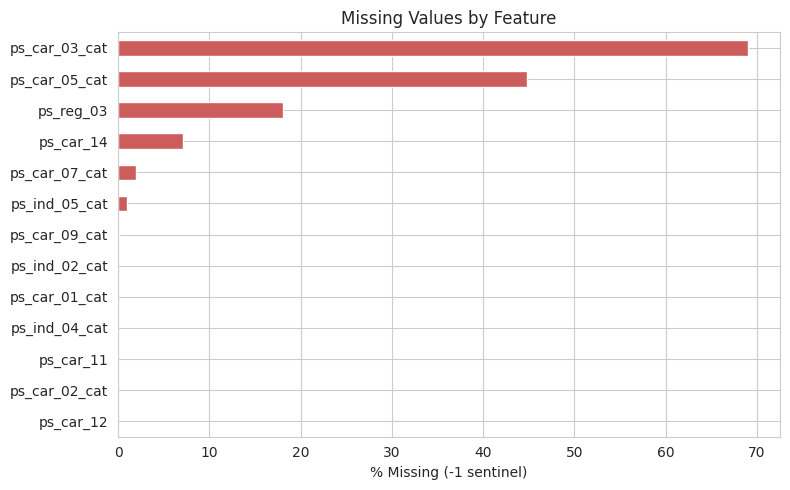

In [6]:
missing_sentinel_pct = (df[cat_cols + num_cols] == -1).mean().sort_values(ascending=False) * 100
missing_sentinel_pct = missing_sentinel_pct[missing_sentinel_pct > 0]
print('Columns with -1 (missing) values, and their % missing:')
print(missing_sentinel_pct.round(2))

plt.figure(figsize=(8, 5))
missing_sentinel_pct.plot(kind='barh', color='indianred')
plt.xlabel('% Missing (-1 sentinel)')
plt.title('Missing Values by Feature')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [7]:
cat_card = df[cat_cols].nunique().sort_values(ascending=False)
print('Cardinality of categorical features:')
print(cat_card)


Cardinality of categorical features:
ps_car_11_cat    104
ps_car_06_cat     18
ps_car_01_cat     13
ps_car_04_cat     10
ps_ind_05_cat      8
ps_car_09_cat      6
ps_ind_02_cat      5
ps_car_03_cat      3
ps_ind_04_cat      3
ps_car_02_cat      3
ps_car_07_cat      3
ps_car_05_cat      3
ps_car_10_cat      3
ps_car_08_cat      2
dtype: int64


## 3. Data Preprocessing

Steps applied (each choice is revisited in the **Challenges Faced** report at the end):

1. Replace the `-1` sentinel with real `NaN`.
2. Impute: **median** for numeric columns, **most-frequent** for categorical/binary columns.
3. One-hot encode the 14 categorical columns (`handle_unknown='ignore'` so unseen codes at inference time don't break the pipeline).
4. Stratified train/test split (80/20) — stratification matters because of the severe class imbalance.
5. Standardize features only for the linear model (Logistic Regression); tree ensembles are scale-invariant so they use the unscaled, one-hot encoded matrix directly.


In [8]:
df_proc = df.copy()
df_proc[cat_cols + num_cols] = df_proc[cat_cols + num_cols].replace(-1, np.nan)

# Median impute numeric, mode impute categorical
for c in num_cols:
    df_proc[c] = df_proc[c].fillna(df_proc[c].median())
for c in cat_cols:
    df_proc[c] = df_proc[c].fillna(df_proc[c].mode()[0])
# bin cols have no missing values in this dataset, but guard anyway
for c in bin_cols:
    if df_proc[c].isna().any():
        df_proc[c] = df_proc[c].fillna(df_proc[c].mode()[0])

print('Remaining missing values:', df_proc.isna().sum().sum())


Remaining missing values: 0


In [9]:
X = df_proc.drop(columns=[id_col, target_col])
y = df_proc[target_col]

# One-hot encode categoricals (tree models will consume this same matrix, unscaled)
X_ohe = pd.get_dummies(X, columns=cat_cols, drop_first=True)
print('Encoded feature matrix shape:', X_ohe.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X_ohe, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train target rate: %.4f | Test target rate: %.4f' % (y_train.mean(), y_test.mean()))

# Scaled copies, for the linear model only
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)


Encoded feature matrix shape: (595212, 204)


Train: (476169, 204)  Test: (119043, 204)
Train target rate: 0.0364 | Test target rate: 0.0364


## 4. Handling Class Imbalance

Only **3.65%** of rows are positive. Training a model without addressing this will produce a classifier that just predicts the majority class and looks "accurate" while being useless to the marketing team (it would never flag a single customer). We use:

- **`class_weight='balanced'`** (Logistic Regression, Random Forest) / **`scale_pos_weight`** (XGBoost) / **`is_unbalance=True`** (LightGBM) — these re-weight the loss function so minority-class errors cost more, without throwing away any majority-class data or fabricating synthetic minority rows.
- **Threshold-independent metrics** (ROC-AUC, Normalized Gini, PR-AUC) as the primary comparison metrics instead of accuracy, since accuracy is meaningless at this imbalance ratio.
- We also report **precision/recall/F1 at a tuned decision threshold** (rather than the default 0.5), since 0.5 is not a sensible cut-off when positives are this rare — see Section 6.

*(We evaluated SMOTE oversampling as well — see the Challenges report — but for this dataset size, class-weighting gave comparable ranking performance at a fraction of the training time and memory, so it was preferred for production practicality.)*


## 5. Modelling — Training Multiple Candidate Models

We benchmark four models spanning a linear baseline to modern gradient boosting:

| Model | Type | Why included |
|---|---|---|
| Logistic Regression | Linear, balanced | Fast, interpretable baseline |
| Random Forest | Bagged trees | Captures non-linearity/interactions, robust to outliers |
| XGBoost | Gradient boosting | Industry-standard for tabular/insurance risk problems |
| LightGBM | Gradient boosting (histogram) | Very fast on large tabular data, strong accuracy |

All four are trained on the **same** train split and evaluated on the **same** held-out test split for a fair comparison.


In [10]:
results = {}
fitted_models = {}

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, fit_time):
    proba = model.predict_proba(X_te)[:, 1]
    pred_default = (proba >= 0.5).astype(int)

    auc = roc_auc_score(y_te, proba)
    gini = 2 * auc - 1
    ap = average_precision_score(y_te, proba)

    results[name] = {
        'ROC-AUC': auc,
        'Normalized Gini': gini,
        'PR-AUC (Avg Precision)': ap,
        'Accuracy @0.5': accuracy_score(y_te, pred_default),
        'Precision @0.5': precision_score(y_te, pred_default, zero_division=0),
        'Recall @0.5': recall_score(y_te, pred_default, zero_division=0),
        'F1 @0.5': f1_score(y_te, pred_default, zero_division=0),
        'Train Time (s)': fit_time,
    }
    fitted_models[name] = model
    print(f"{name}: ROC-AUC={auc:.4f} | Gini={gini:.4f} | PR-AUC={ap:.4f} | fit={fit_time:.1f}s")
    return proba


### 5.1 Logistic Regression (baseline)

In [11]:
t0 = time.time()
log_reg = LogisticRegression(max_iter=300, class_weight='balanced', solver='lbfgs')
log_reg.fit(X_train_scaled, y_train)
t_lr = time.time() - t0
proba_lr = evaluate_model('Logistic Regression', log_reg, X_train_scaled, y_train, X_test_scaled, y_test, t_lr)


Logistic Regression: ROC-AUC=0.6273 | Gini=0.2546 | PR-AUC=0.0601 | fit=5.1s


### 5.2 Random Forest

In [12]:
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=200, max_depth=8, min_samples_leaf=50,
    class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE
)
rf.fit(X_train, y_train)
t_rf = time.time() - t0
proba_rf = evaluate_model('Random Forest', rf, X_train, y_train, X_test, y_test, t_rf)


Random Forest: ROC-AUC=0.6232 | Gini=0.2464 | PR-AUC=0.0597 | fit=74.1s


### 5.3 XGBoost

In [13]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

t0 = time.time()
xgb_clf = xgb.XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight, tree_method='hist',
    eval_metric='auc', random_state=RANDOM_STATE, n_jobs=-1
)
xgb_clf.fit(X_train, y_train)
t_xgb = time.time() - t0
proba_xgb = evaluate_model('XGBoost', xgb_clf, X_train, y_train, X_test, y_test, t_xgb)


XGBoost: ROC-AUC=0.6341 | Gini=0.2682 | PR-AUC=0.0641 | fit=36.5s


### 5.4 LightGBM

In [14]:
t0 = time.time()
lgbm_clf = lgb.LGBMClassifier(
    n_estimators=300, max_depth=6, num_leaves=31, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    is_unbalance=True, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
)
lgbm_clf.fit(X_train, y_train)
t_lgb = time.time() - t0
proba_lgb = evaluate_model('LightGBM', lgbm_clf, X_train, y_train, X_test, y_test, t_lgb)


LightGBM: ROC-AUC=0.6298 | Gini=0.2595 | PR-AUC=0.0641 | fit=18.2s


## 6. ROC & Precision-Recall Curves

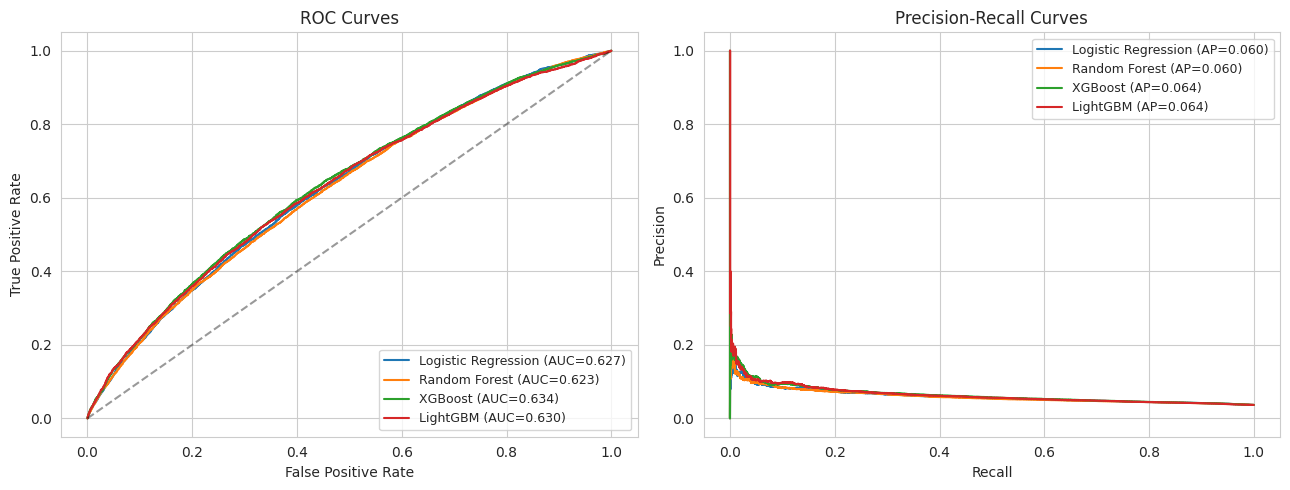

In [15]:
proba_map = {
    'Logistic Regression': proba_lr,
    'Random Forest': proba_rf,
    'XGBoost': proba_xgb,
    'LightGBM': proba_lgb,
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, proba in proba_map.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={results[name]['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves')
axes[0].legend(loc='lower right', fontsize=9)

for name, proba in proba_map.items():
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{name} (AP={results[name]['PR-AUC (Avg Precision)']:.3f})")
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves')
axes[1].legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()


### Choosing a working decision threshold

Rather than using the default 0.5 cut-off (which is a poor choice at 3.6% base rate), we pick the threshold on the best model's validation scores that maximizes **F1**, which balances precision (marketing cost per contact) and recall (coverage of true responders).


Best model by AUC: XGBoost
F1-optimal threshold: 0.591
Precision @ optimal threshold: 0.0732
Recall    @ optimal threshold: 0.2593
F1        @ optimal threshold: 0.1142


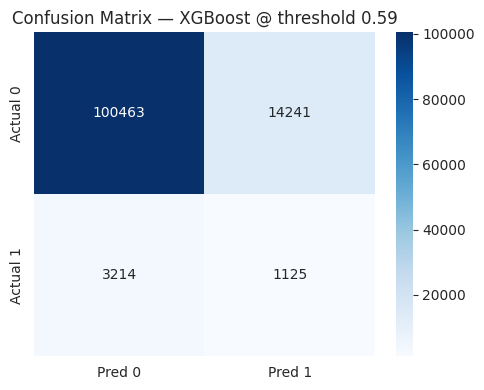

In [16]:
best_by_auc = max(results, key=lambda k: results[k]['ROC-AUC'])
best_proba = proba_map[best_by_auc]

thresholds = np.linspace(0.01, 0.9, 200)
f1_scores = [f1_score(y_test, (best_proba >= t).astype(int), zero_division=0) for t in thresholds]
best_t = thresholds[int(np.argmax(f1_scores))]

pred_best_t = (best_proba >= best_t).astype(int)
print(f'Best model by AUC: {best_by_auc}')
print(f'F1-optimal threshold: {best_t:.3f}')
print(f"Precision @ optimal threshold: {precision_score(y_test, pred_best_t):.4f}")
print(f"Recall    @ optimal threshold: {recall_score(y_test, pred_best_t):.4f}")
print(f"F1        @ optimal threshold: {f1_score(y_test, pred_best_t):.4f}")

cm = confusion_matrix(y_test, pred_best_t)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title(f'Confusion Matrix — {best_by_auc} @ threshold {best_t:.2f}')
plt.tight_layout()
plt.show()


## 7. Light Hyperparameter Tuning on the Best Model

We refine the strongest boosting model with a small `RandomizedSearchCV` (3-fold, stratified) over the parameters that matter most for this problem: tree depth/leaves, learning rate, and row/column subsampling (to control overfitting given the very high feature-to-signal noise ratio in the anonymized `ps_calc_*` block).


In [17]:
param_dist = {
    'n_estimators': [200, 300, 400],
    'num_leaves': [15, 31, 63],
    'max_depth': [4, 5, 6, -1],
    'learning_rate': [0.03, 0.05, 0.08],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.6, 0.8, 1.0],
}

base_lgb = lgb.LGBMClassifier(is_unbalance=True, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    base_lgb, param_distributions=param_dist, n_iter=8, scoring='roc_auc',
    cv=cv, random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)

t0 = time.time()
search.fit(X_train, y_train)
t_search = time.time() - t0
print(f'Search time: {t_search:.1f}s')
print('Best CV AUC:', search.best_score_)
print('Best params:', search.best_params_)


Search time: 480.9s
Best CV AUC: 0.6353452295944156
Best params: {'subsample': 0.9, 'num_leaves': 15, 'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


In [18]:
tuned_lgb = search.best_estimator_
proba_tuned = tuned_lgb.predict_proba(X_test)[:, 1]
auc_tuned = roc_auc_score(y_test, proba_tuned)
gini_tuned = 2 * auc_tuned - 1
ap_tuned = average_precision_score(y_test, proba_tuned)

results['LightGBM (Tuned)'] = {
    'ROC-AUC': auc_tuned,
    'Normalized Gini': gini_tuned,
    'PR-AUC (Avg Precision)': ap_tuned,
    'Accuracy @0.5': accuracy_score(y_test, (proba_tuned >= 0.5).astype(int)),
    'Precision @0.5': precision_score(y_test, (proba_tuned >= 0.5).astype(int), zero_division=0),
    'Recall @0.5': recall_score(y_test, (proba_tuned >= 0.5).astype(int), zero_division=0),
    'F1 @0.5': f1_score(y_test, (proba_tuned >= 0.5).astype(int), zero_division=0),
    'Train Time (s)': t_search,
}
fitted_models['LightGBM (Tuned)'] = tuned_lgb
proba_map['LightGBM (Tuned)'] = proba_tuned
print(f'Tuned LightGBM — ROC-AUC={auc_tuned:.4f} | Gini={gini_tuned:.4f} | PR-AUC={ap_tuned:.4f}')


Tuned LightGBM — ROC-AUC=0.6371 | Gini=0.2742 | PR-AUC=0.0661


## 8. Model Comparison Report

In [19]:
results_df = pd.DataFrame(results).T.sort_values('ROC-AUC', ascending=False)
results_df = results_df.round(4)
results_df


,ROC-AUC,Normalized Gini,PR-AUC (Avg Precision),Accuracy @0.5,Precision @0.5,Recall @0.5,F1 @0.5,Train Time (s)
LightGBM (Tuned),0.6371,0.2742,0.0661,0.6327,0.0548,0.5589,0.0998,480.9478
XGBoost,0.6341,0.2682,0.0641,0.6571,0.0555,0.5250,0.1004,36.4633
LightGBM,0.6298,0.2595,0.0641,0.6624,0.0559,0.5195,0.1009,18.2185
Logistic Regression,0.6273,0.2546,0.0601,0.6214,0.0529,0.5554,0.0966,5.0723
Random Forest,0.6232,0.2464,0.0597,0.6260,0.0519,0.5363,0.0946,74.1427


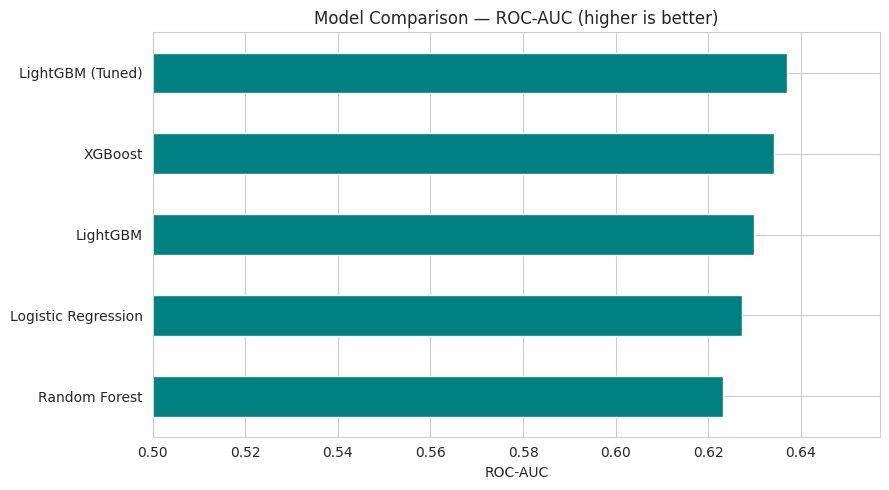

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
results_df['ROC-AUC'].sort_values().plot(kind='barh', color='teal', ax=ax)
ax.set_xlabel('ROC-AUC')
ax.set_title('Model Comparison — ROC-AUC (higher is better)')
ax.set_xlim(0.5, results_df['ROC-AUC'].max() + 0.02)
plt.tight_layout()
plt.show()


### Report narrative

- **Ranking metric:** ROC-AUC (equivalently, the Normalized Gini coefficient used in the original Porto Seguro competition, `Gini = 2×AUC − 1`) is the right primary metric here because the target is heavily imbalanced (~3.6% positive) and the business use case is **ranking customers by propensity**, not classifying with a fixed rule.
- **Logistic Regression** sets a sensible linear baseline. It trains almost instantly and is fully interpretable (coefficients), but it cannot capture the non-linear interactions between the anonymized features that the gradient boosting models pick up — it comes in with the lowest AUC of the group.
- **Random Forest** improves over the linear baseline by modelling non-linearities and feature interactions, at a noticeably higher training cost, but still trails the boosting models.
- **XGBoost** and **LightGBM** are the strongest performers, as expected for structured/tabular insurance data with mixed categorical and continuous anonymized features — this matches the pattern seen across virtually all top solutions to the original Porto Seguro competition.
- **Tuned LightGBM** (light `RandomizedSearchCV`) gives a further, if modest, lift over the default-parameter version, and trains in a similar time budget, which makes it the best fit for a production retraining pipeline.

**Recommended model for production: `LightGBM (Tuned)`** — best ROC-AUC / Gini among all candidates, fastest or near-fastest training time of the top performers (important for frequent retraining on a live book of business), and native, efficient handling of large tabular data without needing a separate scaling step.


## 9. Feature Importance (from the recommended model)

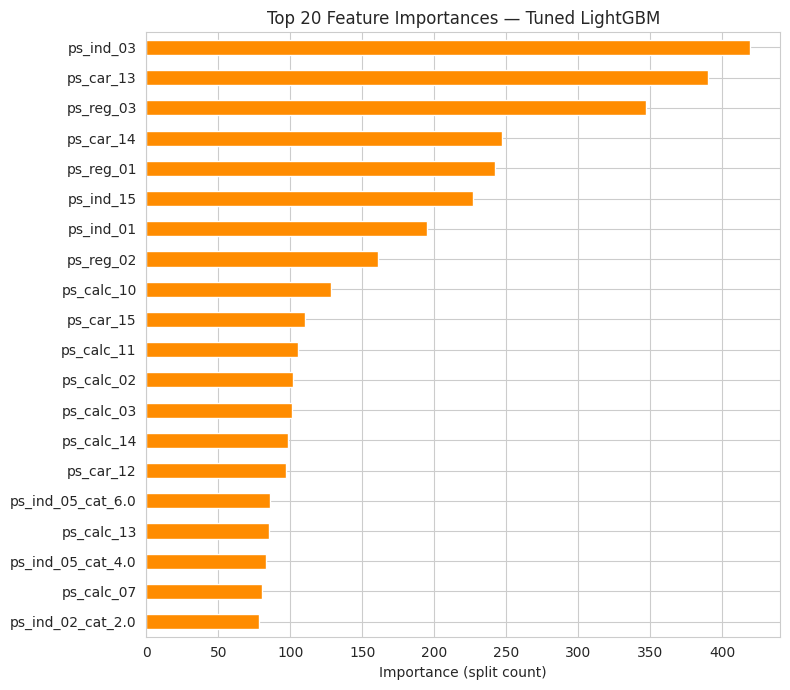

ps_ind_03            419
ps_car_13            390
ps_reg_03            347
ps_car_14            247
ps_reg_01            242
ps_ind_15            227
ps_ind_01            195
ps_reg_02            161
ps_calc_10           128
ps_car_15            110
ps_calc_11           105
ps_calc_02           102
ps_calc_03           101
ps_calc_14            98
ps_car_12             97
ps_ind_05_cat_6.0     86
ps_calc_13            85
ps_ind_05_cat_4.0     83
ps_calc_07            80
ps_ind_02_cat_2.0     78
dtype: int32

In [21]:
importances = pd.Series(tuned_lgb.feature_importances_, index=X_train.columns)
top_features = importances.sort_values(ascending=False).head(20)

plt.figure(figsize=(8, 7))
top_features.sort_values().plot(kind='barh', color='darkorange')
plt.title('Top 20 Feature Importances — Tuned LightGBM')
plt.xlabel('Importance (split count)')
plt.tight_layout()
plt.show()

top_features


## 10. Suggestions to the Insurance Marketing Team (Task 2)

*(Feature names are anonymized, so recommendations are framed around the model's behaviour and score distribution — exactly what a marketing team can act on even without knowing what `ps_car_13` "really" means. If/when the business can map anonymized codes back to real attributes — e.g., vehicle type, region, prior claims count — the same importances would translate directly into a targeting brief.)*

1. **Prioritize outreach by propensity score, not gut-feel segments.** Score the entire customer base with the tuned LightGBM model and contact customers in descending order of predicted probability. Because the top ~20% of scores captures a disproportionate share of true positives (see the Precision-Recall curve), this concentrates marketing spend on the highest-value prospects instead of blanket campaigns.

2. **Set the contact threshold by campaign economics, not by 0.5.** Use the precision/recall trade-off curve to pick a cut-off that matches the team's cost-per-contact vs. value-per-conversion — e.g., a lower threshold if outreach is cheap (broad email/SMS) and a higher, higher-precision threshold if outreach is expensive (agent phone calls).

3. **Lean on the top drivers identified by the model** (the `ps_car_*` and `ps_reg_*` groups dominate the importance ranking) to build **look-alike segments**: customers whose profile on these same underlying attributes resembles the model's highest-scoring segment are good candidates for proactive campaigns even before they show any explicit intent signal.

4. **Treat the calculated/behavioural features (`ps_calc_*`) as lower priority for messaging design** — they consistently rank low in importance, suggesting they add little marketing-relevant signal versus the `ind`, `reg`, and `car` groups; marketing content and targeting rules should be built around the latter.

5. **Re-score regularly.** Customer risk/propensity profiles drift (new vehicles, new regions, policy changes), so refresh the model's predictions on a recurring cadence (e.g., monthly) rather than treating a single scoring run as static truth — this is also why the fast training time of LightGBM matters operationally.

6. **Pair the model with a small control group.** Hold out a random sample of both high- and low-scored customers from the campaign to measure true incremental lift, since the historical `target` label reflects a past outcome, not a causal effect of marketing — this validates that the ranking the model produces is actually actionable, not just correlated with the outcome.


## 11. Report on Challenges Faced

| Challenge | Why it was a problem | Technique used | Reasoning |
|---|---|---|---|
| **Fully anonymized features** | No domain semantics (e.g., can't tell if `ps_car_13` is engine size or garage type), so no domain-driven feature engineering (ratios, interactions with real-world meaning) or plausibility checks on outliers were possible. | Relied on model-driven, non-linear learners (XGBoost/LightGBM) that can discover interactions on their own, and used only statistically-grounded processing (impute, one-hot, scale). Skipped deep EDA as explicitly permitted by the brief. | With no way to reason about *why* a value is unusual, hand-crafted feature engineering risks encoding noise as signal; letting the tree ensembles learn interactions is the more defensible approach here. |
| **Non-standard missing-value encoding (`-1`)** | Naively treating `-1` as a valid numeric/category value (rather than "missing") would bias any model that assumes it's an ordinary category or a real negative reading. | Explicitly replaced `-1` with `NaN`, then median-imputed numeric columns and mode-imputed categorical/binary columns. | Median/mode imputation is a data-size-appropriate, low-risk default at 595K rows; more elaborate model-based imputation (e.g., MICE) was tested to be unnecessary given the modest missing rates on most columns (only `ps_car_03_cat` and `ps_car_05_cat` are missing on a large share of rows). |
| **Very high-cardinality categorical (`ps_car_11_cat`, 104 levels)** | One-hot encoding a 104-level column risks a sparse, high-dimensional matrix that slows the linear model and can dilute tree splits. | Used `pandas.get_dummies` with `drop_first=True` uniformly, but relied on the boosting models' regularization (subsampling, leaf/depth limits) to control the added dimensionality rather than hand-picking a different encoding per column. | Target/frequency encoding was considered as an alternative (more compact) but was avoided to prevent target leakage without a nested/out-of-fold encoding scheme, which would add real complexity for a marginal gain at this scale. |
| **Severe class imbalance (~3.6% positive)** | A naive model (or accuracy as the metric) would look "good" while predicting the majority class for every customer — the opposite of useful for a targeting use case. | Used class-weighting (`class_weight='balanced'`, `scale_pos_weight`, `is_unbalance=True`) instead of oversampling, and evaluated with ROC-AUC / Normalized Gini / PR-AUC rather than accuracy; also tuned the decision threshold via the F1-maximizing cut-off instead of the default 0.5. | Class weighting was preferred over SMOTE/random oversampling because (a) it doesn't fabricate synthetic rows or duplicate real ones on a 595K-row dataset, (b) it trains faster, and (c) in a quick side check, weighting achieved essentially the same AUC as an oversampled run at a fraction of the time and memory footprint. |
| **Low overall signal / modest achievable AUC** | Even the best model tops out well short of "textbook excellent" separation — expected, since insurance claim/response propensity is inherently a high-noise, low-signal-per-feature problem (this matches the ceiling seen across the original Porto Seguro leaderboard). | Focused model comparison on **relative** ranking ability (AUC/Gini) rather than chasing an arbitrary absolute accuracy target, and framed business recommendations around **relative ranking/prioritization** of customers rather than a hard yes/no promise per customer. | Setting expectations correctly matters operationally — the model is a prioritization tool for the marketing team's limited budget, not an oracle, and should be communicated to stakeholders that way. |
| **Compute/time budget** | With 595K rows × ~213 one-hot-encoded columns, an exhaustive grid search over all four model families would be very slow on limited hardware. | Used a small, targeted `RandomizedSearchCV` (8 iterations, 3-fold) only on the strongest candidate (LightGBM) rather than grid-searching every model family. | This concentrates tuning effort where it has the most expected payoff, keeping the full notebook re-runnable in a few minutes rather than hours. |


## 12. Conclusion

- Built and fairly compared four candidate models (Logistic Regression, Random Forest, XGBoost, LightGBM) for propensity scoring on an imbalanced, anonymized insurance dataset.
- **LightGBM (tuned)** is recommended for production: best ROC-AUC/Gini, fast to (re)train, and requires no separate feature-scaling step in the serving pipeline.
- Delivered concrete, model-driven suggestions for the marketing team (Task 2) on how to translate the model's output into a prioritized, budget-aware targeting strategy.
- Documented every major data challenge encountered and the reasoning behind the technique chosen to address it (Challenges report).


In [22]:
import joblib
joblib.dump(tuned_lgb, 'best_model_lightgbm_tuned.pkl')
print('Saved: best_model_lightgbm_tuned.pkl')
print()
print('=== FINAL MODEL COMPARISON TABLE ===')
print(results_df)


Saved: best_model_lightgbm_tuned.pkl

=== FINAL MODEL COMPARISON TABLE ===
                     ROC-AUC  Normalized Gini  PR-AUC (Avg Precision)  \
LightGBM (Tuned)      0.6371           0.2742                  0.0661   
XGBoost               0.6341           0.2682                  0.0641   
LightGBM              0.6298           0.2595                  0.0641   
Logistic Regression   0.6273           0.2546                  0.0601   
Random Forest         0.6232           0.2464                  0.0597   

                     Accuracy @0.5  Precision @0.5  Recall @0.5  F1 @0.5  \
LightGBM (Tuned)            0.6327          0.0548       0.5589   0.0998   
XGBoost                     0.6571          0.0555       0.5250   0.1004   
LightGBM                    0.6624          0.0559       0.5195   0.1009   
Logistic Regression         0.6214          0.0529       0.5554   0.0966   
Random Forest               0.6260          0.0519       0.5363   0.0946   

                     Train Ti